# Airline Passenger Satisfaction ? EDA

We will explore the training data one step at a time and review each result before continuing.

## Step 1: Load and preview the data

First, confirm that the file loads, inspect the number of rows and columns, and preview five records. `satisfaction` is the target column. We will keep the test data separate.

In [2]:
from pathlib import Path
import pandas as pd

pd.set_option("display.max_columns", None)

data_path = Path("data/train.csv")
df = pd.read_csv(data_path)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 699,635
Columns: 23


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


## Step 2: Check column types and missing values

Review each column's stored data type, missing-value count and percentage, and number of distinct non-missing values. Numeric storage does not always mean a continuous measurement: service ratings are ordered categories, and `id` is an identifier. We will inspect these before deciding how to handle them.

In [3]:
column_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2),
    "unique_count": df.nunique(dropna=True),
})

display(column_summary)

,dtype,missing_count,missing_percent,unique_count
id,int64,0,0.00,699635
Age,int64,0,0.00,75
Flight Distance,int64,0,0.00,3474
Inflight wifi service,int64,0,0.00,6
Departure/Arrival time convenient,int64,0,0.00,6
Ease of Online booking,int64,0,0.00,6
Gate location,int64,0,0.00,6
Food and drink,int64,0,0.00,6
Online boarding,int64,0,0.00,6
Seat comfort,int64,0,0.00,6


## Step 3: Check duplicate records

Check duplicate IDs and full rows, then exclude `id` to detect repeated records with different IDs. Also check repeated feature combinations without the target. Repeated features may be legitimate, so these counts alone are not a reason to delete rows.

In [4]:
record_columns = df.columns.drop("id").tolist()
feature_columns = df.columns.drop(["id", "satisfaction"]).tolist()

duplicate_summary = pd.Series({
    "Duplicate IDs": df["id"].duplicated().sum(),
    "Duplicate full rows": df.duplicated().sum(),
    "Duplicate records excluding id": df.duplicated(subset=record_columns).sum(),
    "Duplicate feature combinations excluding id and target": df.duplicated(subset=feature_columns).sum(),
}, name="Count beyond first occurrence")

display(duplicate_summary.to_frame())

,Count beyond first occurrence
Duplicate IDs,0
Duplicate full rows,0
Duplicate records excluding id,0
Duplicate feature combinations excluding id and target,0


## Step 4: Examine the target distribution

Compare the counts and percentages of `False` and `True` in `satisfaction`. This helps us assess class balance before exploring relationships with passenger and service features. Labels below preserve the values in the dataset.

,count,percent
satisfaction,,
False,389296,55.64
True,310339,44.36


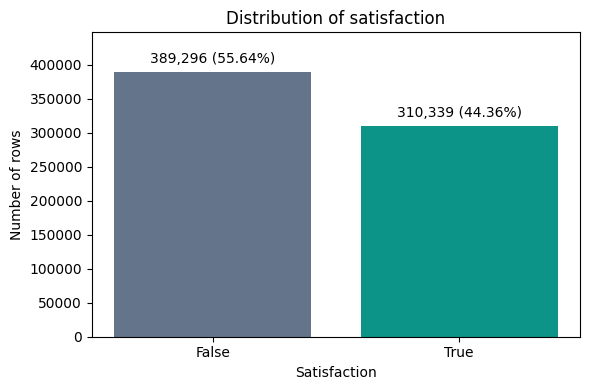

In [5]:
import matplotlib.pyplot as plt

target_counts = df["satisfaction"].value_counts().reindex([False, True], fill_value=0)
target_summary = target_counts.rename("count").to_frame()
target_summary["percent"] = (target_summary["count"] / len(df) * 100).round(2)
display(target_summary)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(target_summary.index.astype(str), target_summary["count"],
              color=["#64748b", "#0d9488"])
ax.set(title="Distribution of satisfaction", xlabel="Satisfaction", ylabel="Number of rows")
ax.bar_label(bars, labels=[f"{count:,} ({percent:.2f}%)"
                         for count, percent in zip(target_summary["count"], target_summary["percent"])],
             padding=4)
ax.set_ylim(0, target_summary["count"].max() * 1.15)
fig.tight_layout()
plt.show()

## Step 5: Explore passenger groups and satisfaction

For each categorical feature, compare group sizes, their percentage of all training rows, and the satisfaction rate within each group. Paired charts show representation and satisfaction on separate scales. These comparisons describe associations, not causation.

Gender


,rows,percent_of_rows,satisfied_count,satisfaction_rate_percent
Gender,,,,
Female,347952,49.73,152401,43.80
Male,351683,50.27,157938,44.91


Customer Type


,rows,percent_of_rows,satisfied_count,satisfaction_rate_percent
Customer Type,,,,
Loyal Customer,576990,82.47,285694,49.51
disloyal Customer,122645,17.53,24645,20.09


Type of Travel


,rows,percent_of_rows,satisfied_count,satisfaction_rate_percent
Type of Travel,,,,
Business travel,497441,71.1,290673,58.43
Personal Travel,202194,28.9,19666,9.73


Class


,rows,percent_of_rows,satisfied_count,satisfaction_rate_percent
Class,,,,
Business,342212,48.91,248210,72.53
Eco,327404,46.80,54859,16.76
Eco Plus,30019,4.29,7270,24.22


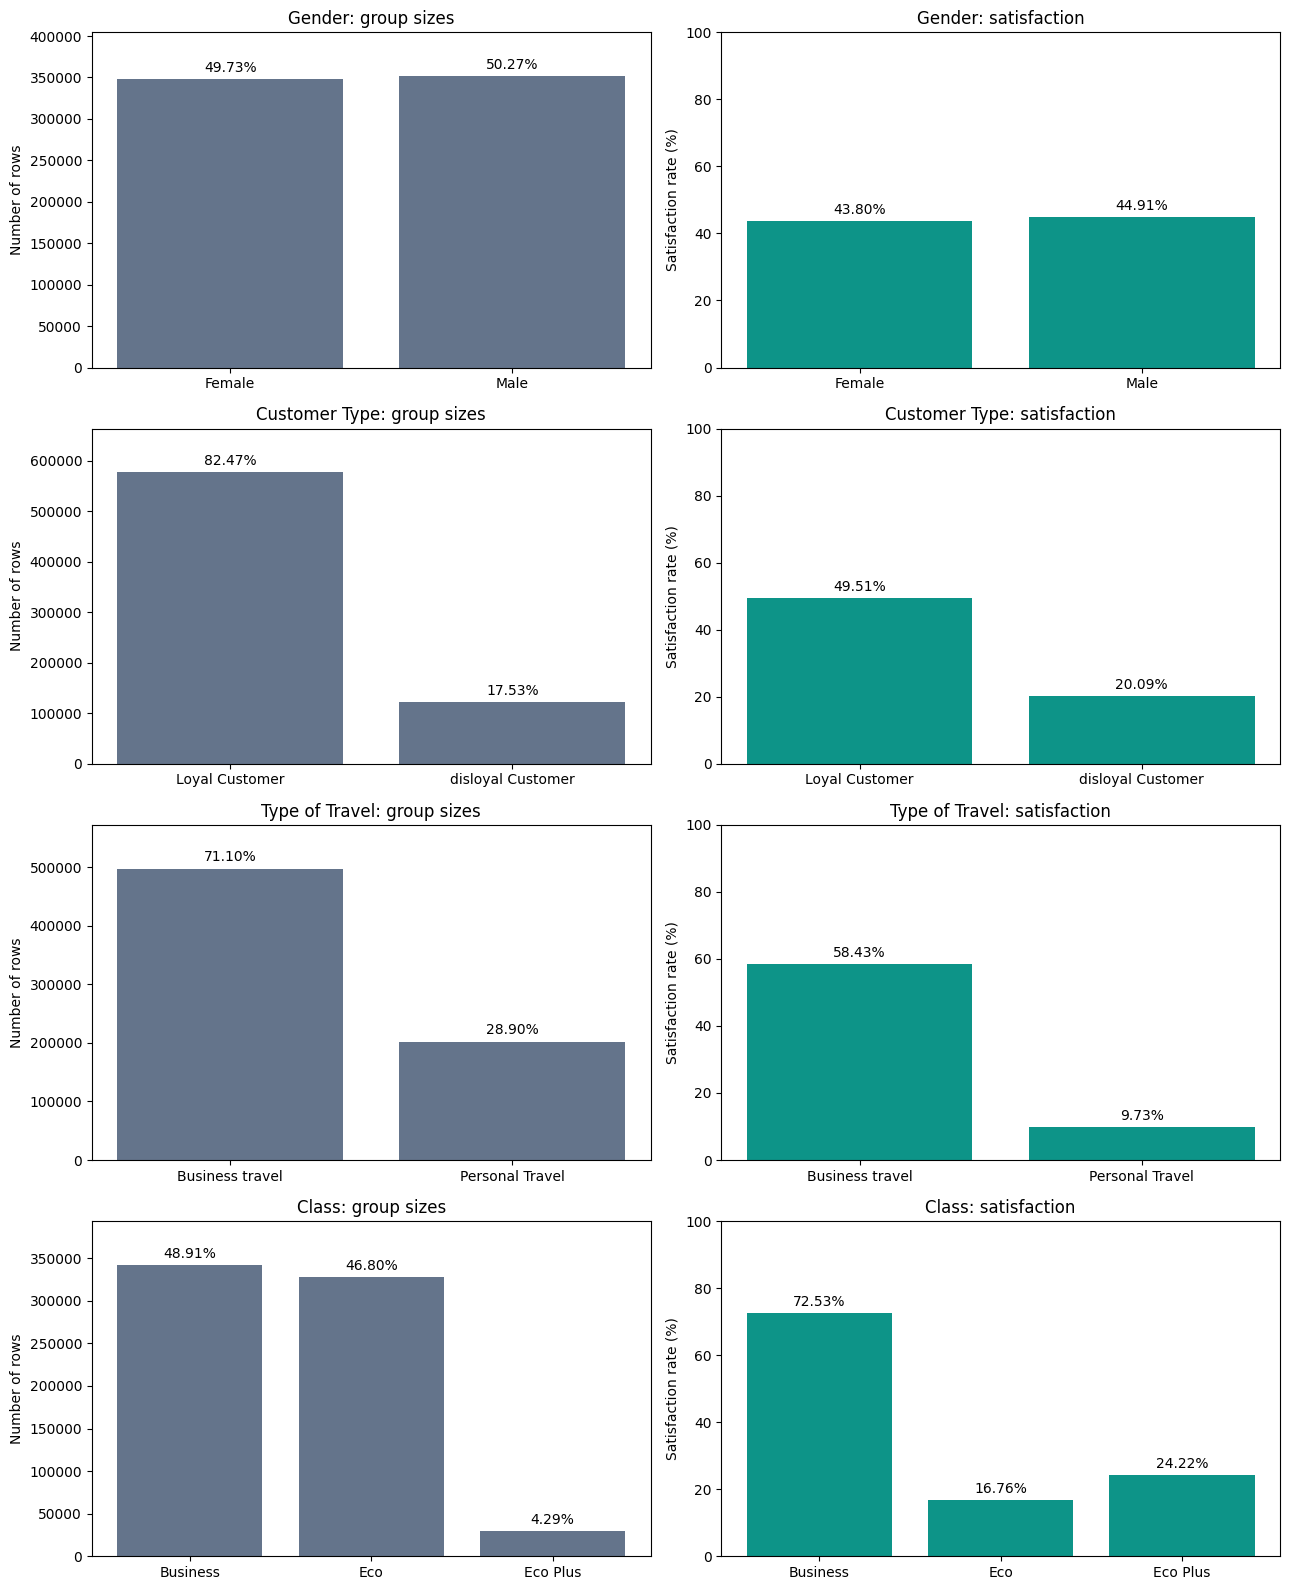

In [9]:
categorical_columns = ["Gender", "Customer Type", "Type of Travel", "Class"]

fig, axes = plt.subplots(len(categorical_columns), 2, figsize=(13, 16))
for col, (count_ax, rate_ax) in zip(categorical_columns, axes):
    group_summary = df.groupby(col, dropna=False, observed=True)["satisfaction"].agg(
        rows="size", satisfied_count="sum", satisfaction_rate="mean"
    )
    group_summary.insert(1, "percent_of_rows", (group_summary["rows"] / len(df) * 100).round(2))
    group_summary["satisfaction_rate_percent"] = (group_summary.pop("satisfaction_rate") * 100).round(2)
    print(col)
    display(group_summary)

    labels = group_summary.index.astype(str)
    bars = count_ax.bar(labels, group_summary["rows"], color="#64748b")
    count_ax.bar_label(bars, labels=[f"{value:.2f}%" for value in group_summary["percent_of_rows"]], padding=3)
    count_ax.set(title=f"{col}: group sizes", ylabel="Number of rows",
                 ylim=(0, group_summary["rows"].max() * 1.15))

    rates = group_summary["satisfaction_rate_percent"]
    bars = rate_ax.bar(labels, rates, color="#0d9488")
    rate_ax.bar_label(bars, labels=[f"{rate:.2f}%" for rate in rates], padding=3)
    rate_ax.set(title=f"{col}: satisfaction", ylabel="Satisfaction rate (%)", ylim=(0, 100))

fig.tight_layout()
plt.show()

## Step 6: Numeric distributions by satisfaction

Compare age, flight distance, and delays for satisfied and dissatisfied passengers. Delays are transformed with `log1p` (natural log of 1 + delay) to include zero values and reduce skew. Each histogram shows the percentage within its group using shared bins. Missing values are excluded; the original data is unchanged.

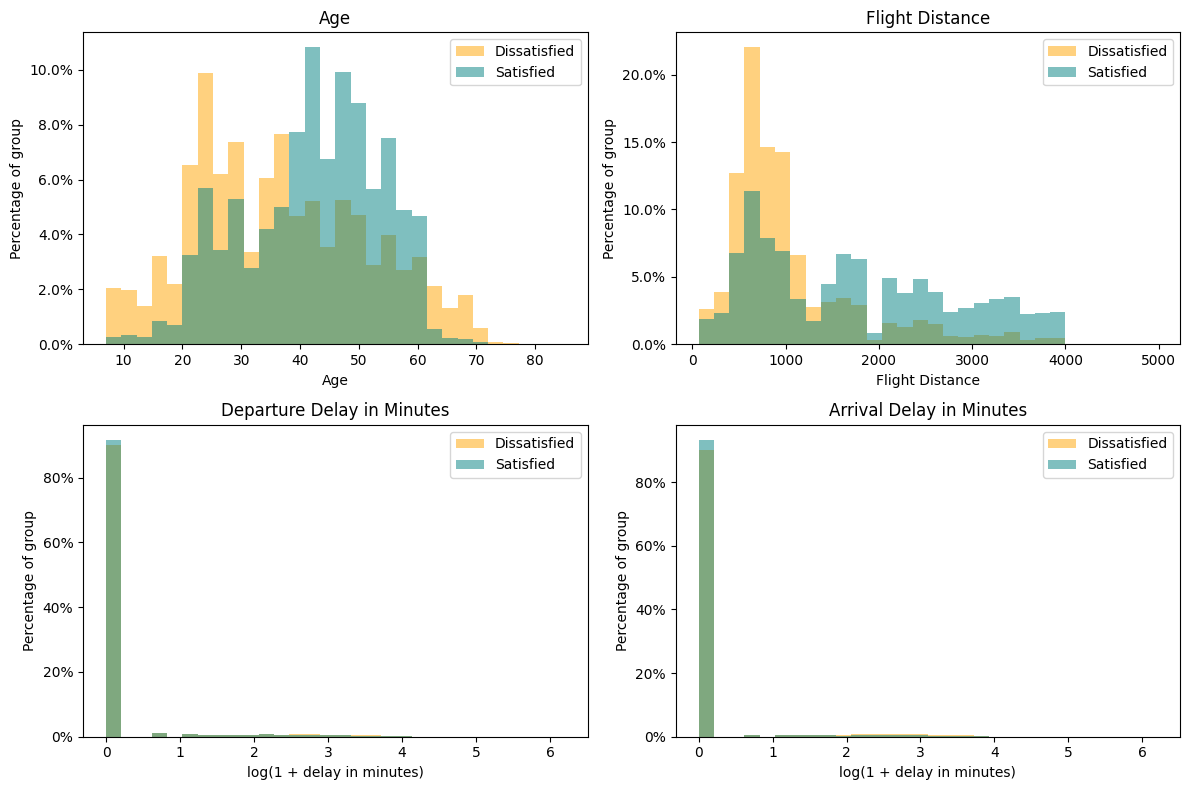

In [14]:
import numpy as np
from matplotlib.ticker import PercentFormatter

continuous_columns = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(continuous_columns, axes.flat):
    is_delay = "Delay" in col
    plot_values = np.log1p(df[col]) if is_delay else df[col]
    bins = np.histogram_bin_edges(plot_values.dropna(), bins=30)
    for target, label, color in [(False, "Dissatisfied", "orange"),
                                  (True, "Satisfied", "teal")]:
        values = plot_values.loc[df["satisfaction"].eq(target)].dropna()
        ax.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)),
                alpha=0.5, label=label, color=color)
    ax.set_title(col)
    ax.set_xlabel("log(1 + delay in minutes)" if is_delay else col)
    ax.set_ylabel("Percentage of group")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()

plt.tight_layout()
plt.show()


## Step 7: Numeric correlation heatmap

Pearson correlations for numeric features, service ratings, and satisfaction (False = 0, True = 1). Text categories and `id` are excluded. Only the lower half is shown to avoid repeating values. Delays use original minutes; ratings are treated as equally spaced scores. Correlation measures linear association, not causation. Missing values are handled pairwise.

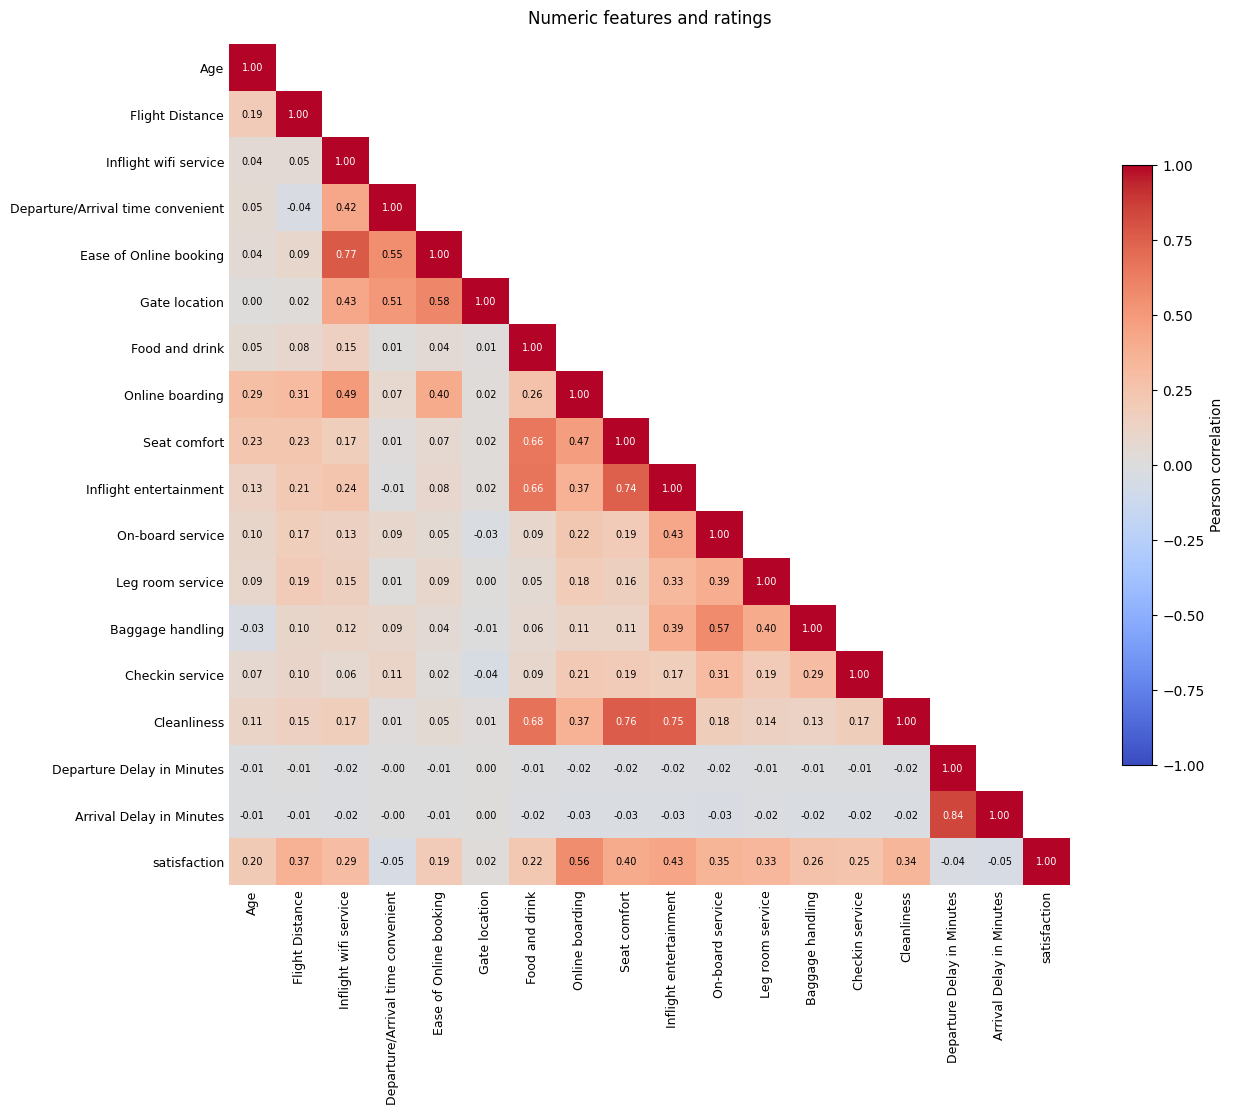

In [17]:
import numpy as np

correlation_data = df.select_dtypes(include=["number", "bool"]).drop(columns="id", errors="ignore")
correlation = correlation_data.corr()
mask = np.triu(np.ones(correlation.shape, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(13, 11))
heatmap = ax.imshow(np.ma.array(correlation.to_numpy(), mask=mask),
                    cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), labels=correlation.columns,
              rotation=90, fontsize=9)
ax.set_yticks(range(len(correlation)), labels=correlation.index, fontsize=9)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

for row in range(len(correlation)):
    for col in range(row + 1):
        value = correlation.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(value) > 0.6 else "black")

fig.colorbar(heatmap, ax=ax, label="Pearson correlation", shrink=0.7)
ax.set_title("Numeric features and ratings", pad=15)
plt.tight_layout()
plt.show()
